<a href="https://colab.research.google.com/github/apsarak26/capstone_project_CS5998/blob/main/Explainable_AI_SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable AI using SHAP

This notebook uses SHAP to understand the predictions made
by the selected XGBoost model.

The analysis focuses on identifying important features and
understanding how they influence individual predictions.

Both global and individual explanations are explored to
better understand the model's behaviour and limitations.

In [1]:
import os
import json
import shap
import xgboost as xgb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.special import expit
from xgboost import XGBClassifier

from google.colab import drive

drive.mount("/content/drive")

print("SHAP version:", shap.__version__)
print("XGBoost version:", xgb.__version__)

Mounted at /content/drive
SHAP version: 0.54.1
XGBoost version: 3.4.1


In [3]:
data_dir = "/content/drive/MyDrive/model_processed/pilot_2014q1"

results_dir = "/content/drive/MyDrive/model_results/pilot_2014q1"

xgb_dir = f"{results_dir}/xgboost"
comparison_dir = f"{results_dir}/model_comparison"

shap_dir = f"{results_dir}/explainability"

os.makedirs(shap_dir, exist_ok=True)
os.makedirs(f"{shap_dir}/figures", exist_ok=True)

print("Folders ready.")

Folders ready.


In [4]:
with open(f"{comparison_dir}/model_selection.json", "r") as file:
    model_selection = json.load(file)

selected_model = model_selection["selected_model"]
experiment = model_selection["selected_experiment"]
threshold = model_selection["classification_threshold"]

print("Selected model:", selected_model)
print("Feature set:", experiment)
print("Classification threshold:", threshold)

Selected model: XGBoost
Feature set: E3_Contextual
Classification threshold: 0.7937632


Load the trained XGBoost model

In [5]:
model = XGBClassifier()

model.load_model(
    f"{xgb_dir}/models/{experiment}_xgboost.json"
)

print("Model loaded successfully.")
print("Best iteration:", model.best_iteration)
print("Number of features:", model.n_features_in_)

Model loaded successfully.
Best iteration: 498
Number of features: 1664


Load test data and feature names

In [6]:
X_test = sparse.load_npz(
    f"{data_dir}/{experiment}/X_test.npz"
)

y_test = np.load(
    f"{data_dir}/targets/y_test.npy"
)

with open(
    f"{data_dir}/{experiment}/feature_names.json", "r"
) as file:
    feature_names = json.load(file)

assert X_test.shape[1] == len(feature_names)
assert X_test.shape[0] == len(y_test)
assert X_test.shape[1] == model.n_features_in_

print("Test dataset shape:", X_test.shape)
print("Number of features:", len(feature_names))
print("Negative reports:", (y_test == 0).sum())
print("Positive reports:", (y_test == 1).sum())

print("\nFirst 10 features:")
print(feature_names[:10])

Test dataset shape: (37687, 1664)
Number of features: 1664
Negative reports: 36888
Positive reports: 799

First 10 features:
['drug__standard_concept_id_1000560', 'drug__standard_concept_id_1000632', 'drug__standard_concept_id_1000772', 'drug__standard_concept_id_1101554', 'drug__standard_concept_id_1101898', 'drug__standard_concept_id_1103006', 'drug__standard_concept_id_1103314', 'drug__standard_concept_id_1103640', 'drug__standard_concept_id_1106776', 'drug__standard_concept_id_1107830']


Verify model predictions

In [7]:
test_probabilities = model.predict_proba(X_test)[:, 1]

saved_probabilities = np.load(
    f"{comparison_dir}/predictions/"
    f"xgboost_{experiment}_test_probabilities.npy"
)

assert np.allclose(test_probabilities, saved_probabilities)

test_predictions = (
    test_probabilities >= threshold
).astype(int)

print("Model predictions verified successfully.")
print("Predicted positive reports:", test_predictions.sum())
print("Predicted negative reports:", (test_predictions == 0).sum())

Model predictions verified successfully.
Predicted positive reports: 580
Predicted negative reports: 37107


Prepare SHAP analysis

In [8]:
RANDOM_STATE = 42
SAMPLE_SIZE = 2000

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    X_test.shape[0],
    size=SAMPLE_SIZE,
    replace=False
)

X_shap = X_test[sample_indices]
y_shap = y_test[sample_indices]

print("SHAP sample shape:", X_shap.shape)
print("Negative reports:", (y_shap == 0).sum())
print("Positive reports:", (y_shap == 1).sum())

SHAP sample shape: (2000, 1664)
Negative reports: 1950
Positive reports: 50


In [9]:
booster = model.get_booster()

shap_data = xgb.DMatrix(X_shap)

shap_contributions = booster.predict(
    shap_data,
    pred_contribs=True,
    iteration_range=(0, model.best_iteration + 1)
)

shap_values = shap_contributions[:, :-1]
base_values = shap_contributions[:, -1]

print("SHAP values shape:", shap_values.shape)
print("Base values shape:", base_values.shape)

print("SHAP values calculated successfully.")

SHAP values shape: (2000, 1664)
Base values shape: (2000,)
SHAP values calculated successfully.


In [10]:
raw_scores = base_values + shap_values.sum(axis=1)

shap_probabilities = expit(raw_scores)

original_probabilities = model.predict_proba(X_shap)[:, 1]

max_difference = np.max(
    np.abs(shap_probabilities - original_probabilities)
)

print("Maximum prediction difference:", max_difference)

assert np.allclose(
    shap_probabilities,
    original_probabilities,
    atol=1e-5
)

print("SHAP calculations verified successfully.")

Maximum prediction difference: 2.9802322e-07
SHAP calculations verified successfully.


Calculate global feature importance

In [11]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0),
    "Mean_SHAP": shap_values.mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(20))

,Feature,Mean_Absolute_SHAP,Mean_SHAP
0,categorical__dose_freq_clean_MISSING,0.243094,-0.056023
1,categorical__route_clean_MISSING,0.174068,-0.062594
2,categorical__gender_clean_Female,0.158070,-0.022169
3,numerical__total_drug_count,0.093829,-0.031593
4,drug__standard_concept_id_1119119,0.086883,-0.010128
5,categorical__dose_form_clean_MISSING,0.077624,-0.015430
6,categorical__route_clean_ORAL,0.068338,-0.017521
7,categorical__route_clean_INTRAVENOUS,0.061615,-0.025457
8,numerical__age_years,0.058591,-0.033006
9,numerical__concomitant_drug_count,0.040285,-0.025027


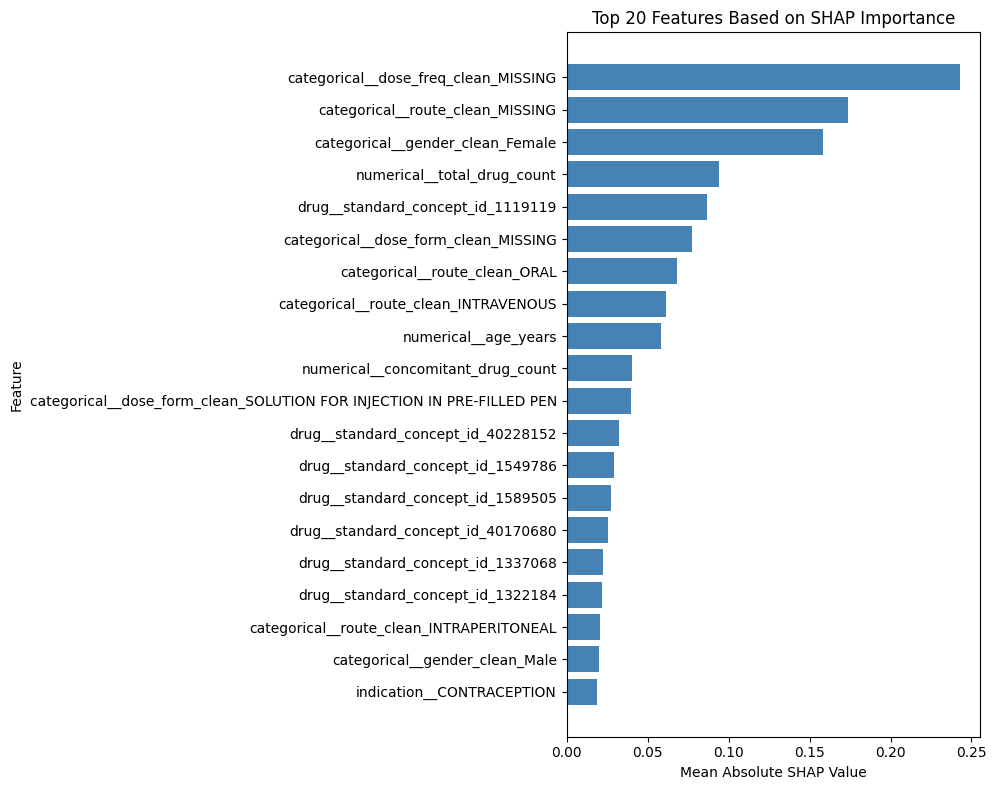

In [12]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title("Top 20 Features Based on SHAP Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    f"{shap_dir}/figures/global_feature_importance.png",
    dpi=300
)

plt.show()

Group features by category

In [13]:
def get_feature_group(feature):

    if feature.startswith("drug__"):
        return "Drug"

    elif feature.startswith("numerical__"):
        return "Numerical"

    elif feature.startswith("categorical__"):
        return "Categorical"

    elif feature.startswith("indication__"):
        return "Indication"

    else:
        return "Other"


feature_importance["Feature_Group"] = (
    feature_importance["Feature"].apply(get_feature_group)
)

display(
    feature_importance["Feature_Group"].value_counts()
)

,count
Feature_Group,
Drug,673
Indication,658
Categorical,330
Numerical,3


In [14]:
group_importance = feature_importance.groupby(
    "Feature_Group"
).agg(
    Feature_Count=("Feature", "count"),
    Total_Importance=("Mean_Absolute_SHAP", "sum"),
    Average_Importance=("Mean_Absolute_SHAP", "mean")
).reset_index()

group_importance["Importance_Percentage"] = (
    group_importance["Total_Importance"] /
    group_importance["Total_Importance"].sum()
) * 100

group_importance = group_importance.sort_values(
    "Total_Importance",
    ascending=False
)

display(group_importance.round(4))

,Feature_Group,Feature_Count,Total_Importance,Average_Importance,Importance_Percentage
0,Categorical,330,1.0607,0.0032,49.306000
1,Drug,673,0.7248,0.0011,33.692299
3,Numerical,3,0.1927,0.0642,8.957600
2,Indication,658,0.1731,0.0003,8.044200


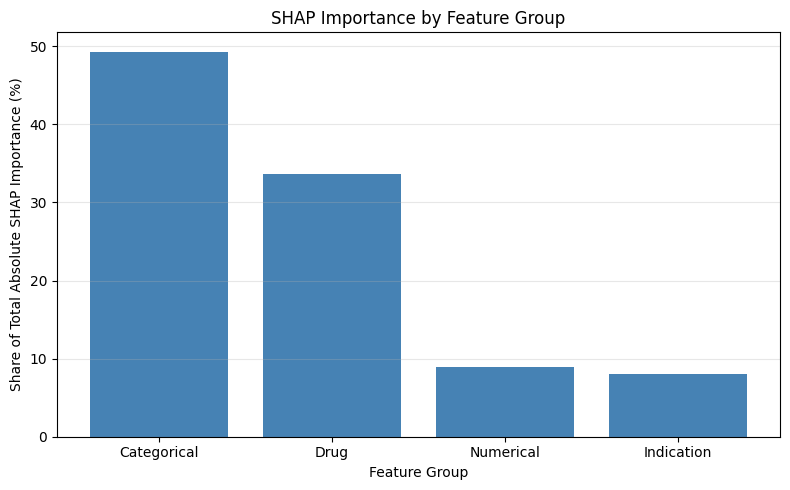

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    group_importance["Feature_Group"],
    group_importance["Importance_Percentage"],
    color="steelblue"
)

plt.title("SHAP Importance by Feature Group")
plt.xlabel("Feature Group")
plt.ylabel("Share of Total Absolute SHAP Importance (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{shap_dir}/figures/grouped_feature_importance.png",
    dpi=300
)

plt.show()

In [16]:
shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=X_shap.toarray(),
    feature_names=feature_names
)

print("SHAP explanation object created.")

SHAP explanation object created.


Generate SHAP beeswarm plot

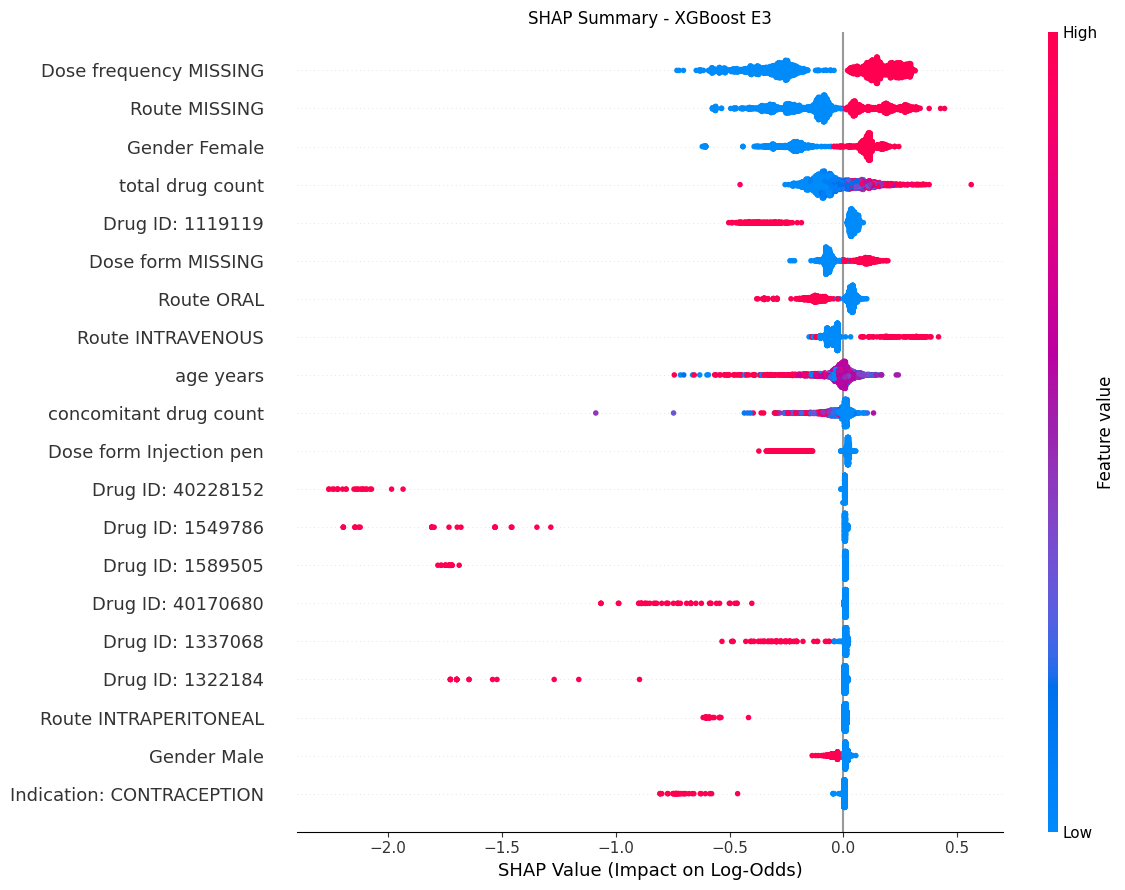

In [18]:
def clean_feature_name(name):

    name = name.replace("categorical__", "")
    name = name.replace("numerical__", "")
    name = name.replace("drug__standard_concept_id_", "Drug ID: ")
    name = name.replace("indication__", "Indication: ")

    name = name.replace("dose_freq_clean", "Dose frequency")
    name = name.replace("dose_form_clean", "Dose form")
    name = name.replace("route_clean", "Route")
    name = name.replace("gender_clean", "Gender")

    name = name.replace(
        "SOLUTION FOR INJECTION IN PRE-FILLED PEN",
        "Injection pen"
    )

    return name.replace("_", " ")


display_names = [
    clean_feature_name(name)
    for name in feature_names
]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=X_shap.toarray(),
    feature_names=display_names
)

shap.plots.beeswarm(
    shap_explanation,
    max_display=20,
    plot_size=(12, 9),
    group_remaining_features=False,
    show=False
)

plt.title("SHAP Summary - XGBoost E3")
plt.xlabel("SHAP Value (Impact on Log-Odds)")
plt.tight_layout()

plt.savefig(
    f"{shap_dir}/figures/shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify prediction categories

In [19]:
prediction_groups = {
    "True Positive": np.where(
        (y_test == 1) & (test_predictions == 1)
    )[0],

    "True Negative": np.where(
        (y_test == 0) & (test_predictions == 0)
    )[0],

    "False Positive": np.where(
        (y_test == 0) & (test_predictions == 1)
    )[0],

    "False Negative": np.where(
        (y_test == 1) & (test_predictions == 0)
    )[0]
}

for group, indices in prediction_groups.items():
    print(group, ":", len(indices))

True Positive : 197
True Negative : 36505
False Positive : 383
False Negative : 602


In [20]:
rng = np.random.default_rng(42)

selected_cases = {}

for group, indices in prediction_groups.items():
    selected_cases[group] = int(rng.choice(indices))

case_summary = []

for group, index in selected_cases.items():

    case_summary.append({
        "Category": group,
        "Test_Index": index,
        "Actual_Label": int(y_test[index]),
        "Predicted_Label": int(test_predictions[index]),
        "Model_Score": float(test_probabilities[index])
    })

case_summary = pd.DataFrame(case_summary)

display(case_summary.round(4))

,Category,Test_Index,Actual_Label,Predicted_Label,Model_Score
0,True Positive,3311,1,1,0.9158
1,True Negative,29180,0,0,0.3853
2,False Positive,23453,0,1,0.8311
3,False Negative,15717,1,0,0.5713


In [21]:
case_indices = list(selected_cases.values())

X_cases = X_test[case_indices]

case_contributions = booster.predict(
    xgb.DMatrix(X_cases),
    pred_contribs=True,
    iteration_range=(0, model.best_iteration + 1)
)

case_shap_values = case_contributions[:, :-1]
case_base_values = case_contributions[:, -1]

case_explanation = shap.Explanation(
    values=case_shap_values,
    base_values=case_base_values,
    data=X_cases.toarray(),
    feature_names=display_names
)

case_probabilities = expit(
    case_base_values + case_shap_values.sum(axis=1)
)

assert np.allclose(
    case_probabilities,
    test_probabilities[case_indices],
    atol=1e-5
)

print("Individual SHAP explanations verified.")

Individual SHAP explanations verified.


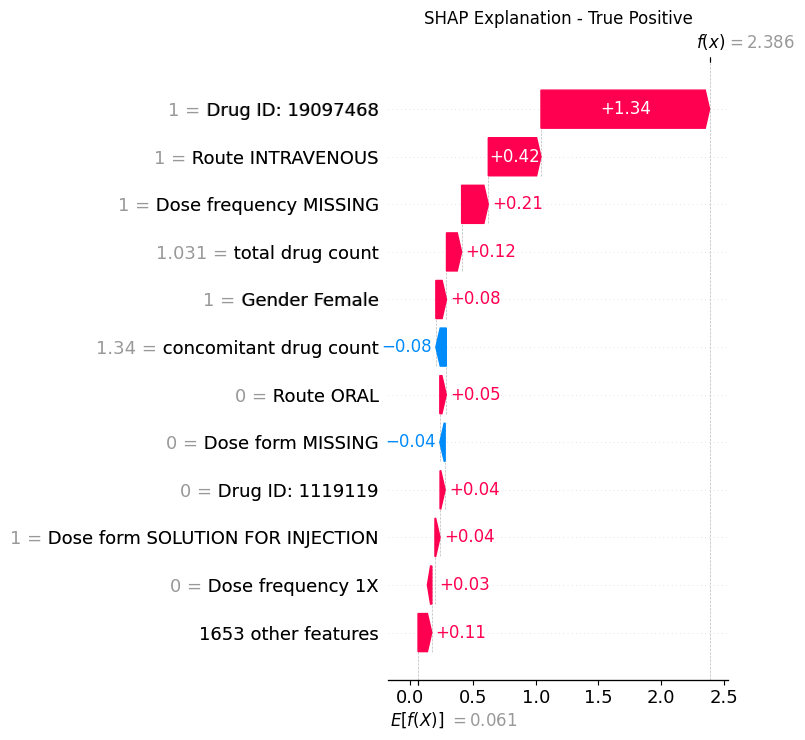

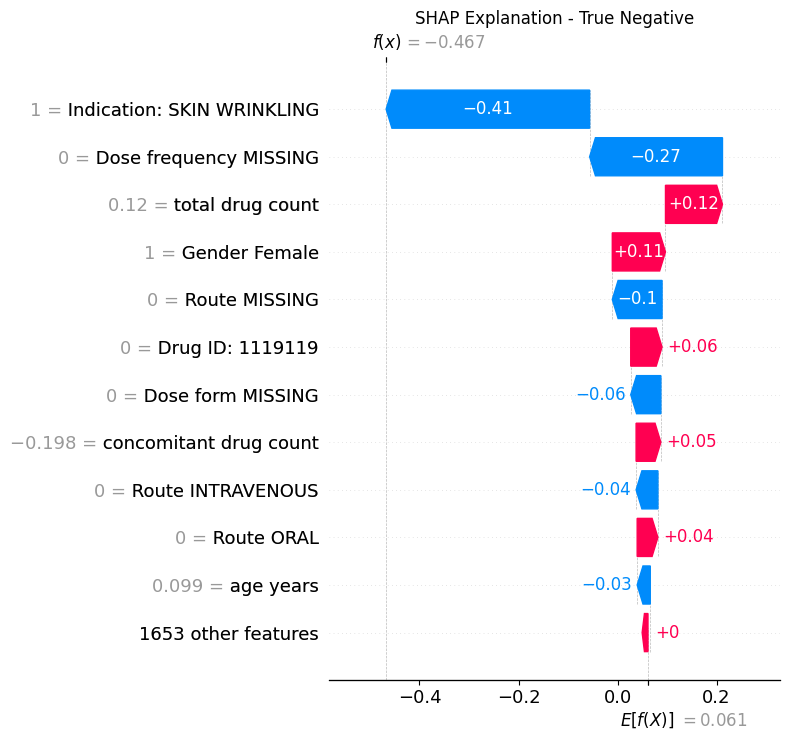

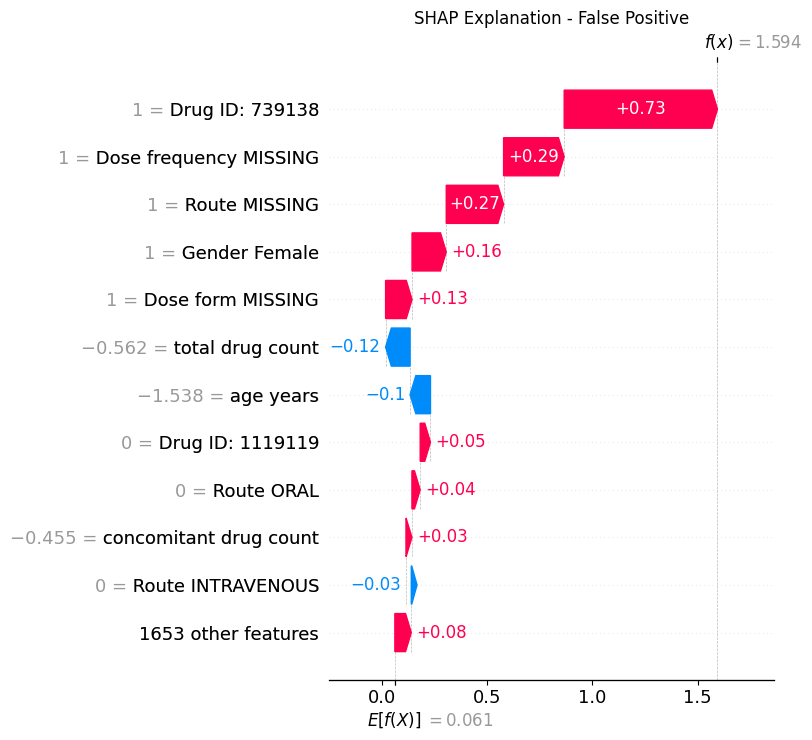

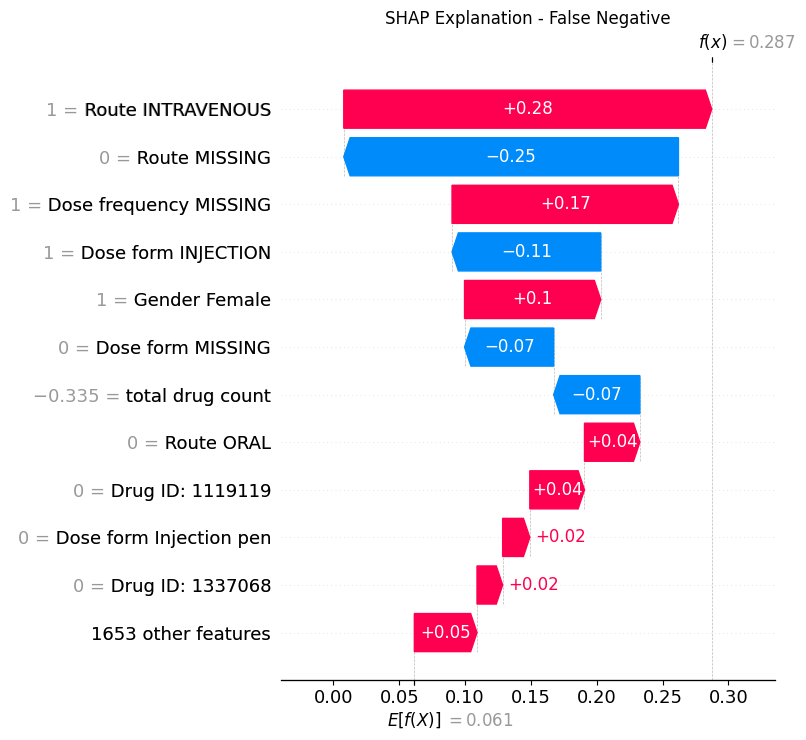

In [22]:
for i, group in enumerate(selected_cases):

    shap.plots.waterfall(
        case_explanation[i],
        max_display=12,
        show=False
    )

    plt.title(f"SHAP Explanation - {group}")
    plt.tight_layout()

    filename = group.lower().replace(" ", "_")

    plt.savefig(
        f"{shap_dir}/figures/shap_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Analyze missing information

In [23]:
missing_features = [
    "categorical__dose_freq_clean_MISSING",
    "categorical__route_clean_MISSING",
    "categorical__dose_form_clean_MISSING"
]

missing_analysis = []

for feature in missing_features:

    index = feature_names.index(feature)

    values = X_test[:, index].toarray().ravel()

    missing_analysis.append({
        "Feature": clean_feature_name(feature),

        "Negative_Reports_Missing_Pct":
            values[y_test == 0].mean() * 100,

        "Positive_Reports_Missing_Pct":
            values[y_test == 1].mean() * 100
    })

missing_analysis = pd.DataFrame(missing_analysis)

display(missing_analysis.round(2))

,Feature,Negative_Reports_Missing_Pct,Positive_Reports_Missing_Pct
0,Dose frequency MISSING,53.830002,70.709999
1,Route MISSING,35.430000,56.950001
2,Dose form MISSING,30.730000,46.560001


Visualize missing information by class

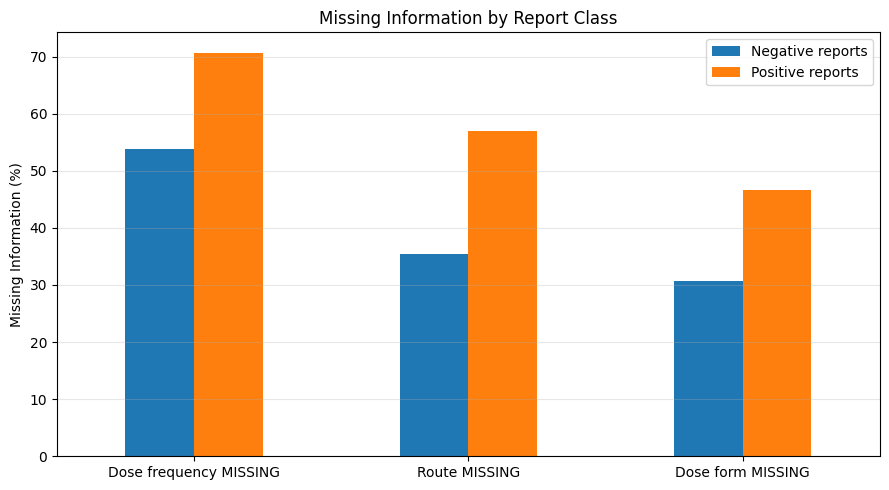

In [24]:
missing_analysis.set_index("Feature").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Missing Information by Report Class")
plt.ylabel("Missing Information (%)")
plt.xlabel("")
plt.xticks(rotation=0)

plt.legend([
    "Negative reports",
    "Positive reports"
])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{shap_dir}/figures/missing_information_by_class.png",
    dpi=300
)

plt.show()

Save analysis tables

In [26]:
feature_importance.to_csv(
    f"{shap_dir}/global_feature_importance.csv",
    index=False
)

group_importance.to_csv(
    f"{shap_dir}/grouped_feature_importance.csv",
    index=False
)

case_summary.to_csv(
    f"{shap_dir}/individual_case_summary.csv",
    index=False
)

missing_analysis.to_csv(
    f"{shap_dir}/missing_information_analysis.csv",
    index=False
)

print("SHAP analysis tables saved successfully.")

SHAP analysis tables saved successfully.


In [27]:
np.savez_compressed(
    f"{shap_dir}/global_shap_values.npz",
    shap_values=shap_values,
    base_values=base_values,
    sample_indices=sample_indices,
    labels=y_shap
)

np.savez_compressed(
    f"{shap_dir}/individual_shap_values.npz",
    shap_values=case_shap_values,
    base_values=case_base_values,
    case_indices=case_indices
)

print("SHAP values saved successfully.")

SHAP values saved successfully.


In [28]:
shap_config = {
    "model": selected_model,
    "experiment": experiment,
    "method": "XGBoost TreeSHAP",
    "dataset": "Test",
    "sample_size": int(len(sample_indices)),
    "number_of_features": int(len(feature_names)),
    "random_state": 42,
    "classification_threshold": float(threshold),
    "best_iteration": int(model.best_iteration),
    "output_scale": "Log-odds",
    "maximum_prediction_difference": float(max_difference),
    "selected_cases": selected_cases,
    "feature_names": feature_names,
    "display_names": display_names,
    "shap_version": shap.__version__,
    "xgboost_version": xgb.__version__
}

with open(f"{shap_dir}/shap_config.json", "w") as file:
    json.dump(shap_config, file, indent=4)

print("Explainability configuration saved.")

Explainability configuration saved.


In [29]:
saved_shap = np.load(
    f"{shap_dir}/global_shap_values.npz"
)

assert np.array_equal(
    saved_shap["shap_values"],
    shap_values
)

assert np.array_equal(
    saved_shap["base_values"],
    base_values
)

assert np.array_equal(
    saved_shap["sample_indices"],
    sample_indices
)

saved_cases = np.load(
    f"{shap_dir}/individual_shap_values.npz"
)

assert np.array_equal(
    saved_cases["shap_values"],
    case_shap_values
)

print("Saved SHAP values verified successfully.")

print("\nSaved files:")

for root, folders, files in os.walk(shap_dir):
    for filename in sorted(files):
        print(os.path.relpath(
            os.path.join(root, filename),
            shap_dir
        ))

print("\nExplainability analysis completed successfully.")

Saved SHAP values verified successfully.

Saved files:
global_feature_importance.csv
global_shap_values.npz
grouped_feature_importance.csv
individual_case_summary.csv
individual_shap_values.npz
missing_information_analysis.csv
shap_config.json
figures/global_feature_importance.png
figures/grouped_feature_importance.png
figures/missing_information_by_class.png
figures/shap_false_negative.png
figures/shap_false_positive.png
figures/shap_summary_plot.png
figures/shap_true_negative.png
figures/shap_true_positive.png

Explainability analysis completed successfully.


### Explainable AI – Primary Findings

SHAP was used to understand the predictions made by the selected XGBoost model with the contextual feature set (E3). The global analysis was performed using a randomly selected sample of 2,000 test reports containing 1,664 encoded features.

The SHAP calculations were verified by reconstructing the model predictions. The maximum difference between the reconstructed and original predictions was approximately 2.98 × 10⁻⁷.

Missing dose frequency, missing administration route, gender, total drug count and individual drug concepts were identified as important features influencing the model predictions.

Categorical features accounted for 49.31% of the total absolute SHAP importance, followed by drug features (33.69%), numerical features (8.96%) and indication features (8.04%).

Although the numerical group contained only three features, these features made a noticeable contribution to the model predictions.

The SHAP summary plot showed that missing dose frequency, administration route and dose form generally increased the model's predicted hypersensitivity score.

Further analysis showed that these fields had higher missing rates in hypersensitivity-related reports than in negative reports. This suggests that the model may partly rely on differences in reporting completeness rather than only drug and patient characteristics.

Individual SHAP explanations were generated for true positive, true negative, false positive and false negative predictions. These examples helped illustrate how different feature contributions influenced the final classification.

The findings demonstrate the importance of explainability in identifying potential limitations that may not be apparent from model evaluation metrics alone.

However, these explanations represent associations learned from the pilot dataset and should not be interpreted as causal relationships or clinically validated risk factors.

Further investigation using additional data, temporal validation and controlled feature ablation experiments is needed to assess the influence of reporting patterns and improve model generalizability.